Paso 1. Abre el archivo de datos y estudia la información general 

Ruta de archivo:

/datasets/games.csv . Descarga el dataset



In [2]:
import pandas as pd
games= pd.read_csv('/Users/edwinmartinezr/Documents/Python Excersice/games.csv',sep=',')

In [3]:
print(games.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB
None


Paso 2. Prepara los datos

Reemplaza los nombres de las columnas (ponlos en minúsculas).


In [4]:
games.columns= games.columns.str.lower()

games.columns

games.head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


In [5]:
#Convierte los datos en los tipos necesarios.
import numpy as np

games['year_of_release'] = games['year_of_release'].astype('Int64')  

games['user_score'] = games['user_score'].replace('tbd', np.nan)  # reemplaza "tbd"
games['user_score'] = games['user_score'].astype(float)

#Describe las columnas en las que los tipos de datos han sido cambiados y explica por qué.

En la columna year of release deberia ser un numero entero y no decimal como aparece en principio y la columna user score la puntuacion deberia ser en valores numericos pero tienen texto.

In [6]:
#Explica por qué rellenaste los valores ausentes como lo hiciste o por qué decidiste dejarlos en blanco.

games.isna().sum()



name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
dtype: int64

In [7]:
games['year_of_release'] = games['year_of_release'].fillna (0)

games['critic_score'] = games['critic_score'].fillna(games['critic_score'].median())

games['user_score'] = games['user_score'].fillna(games['user_score'].mean())

games['rating']= games['rating'].fillna('NaN')

games.isna().sum()


name               2
platform           0
year_of_release    0
genre              2
na_sales           0
eu_sales           0
jp_sales           0
other_sales        0
critic_score       0
user_score         0
rating             0
dtype: int64

#¿Por qué crees que los valores están ausentes? Brinda explicaciones posibles.

Tenemos 4 columnas las cuales tienen valores ausentes en gran cantidad, segun podemos ver,estos datos pueden estar incompletos por razones externas donde no se obtuvo la calificacion por parte de los usuarios, criticos, lo que es algo que no se puede controlar por lo cual recurrimos a los metodos anteriores para rellnar estos valores, tomando en cuenta la informacion de los valores que ya se tenia.

In [8]:
#Calcula las ventas totales (la suma de las ventas en todas las regiones) para cada juego y coloca estos valores en una columna separada.

games['total_sales'] =(
    games['na_sales']+
    games['eu_sales']+
    games['jp_sales']
)

games['total_sales']

games.head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.000000,E,74.09
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,71.0,7.125046,NaN,39.47
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.300000,E,32.23
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.000000,E,29.82
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,71.0,7.125046,NaN,30.38
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,71.0,7.125046,NaN,29.68
6,New Super Mario Bros.,DS,2006,Platform,11.28,9.14,6.50,2.88,89.0,8.500000,E,26.92
7,Wii Play,Wii,2006,Misc,13.96,9.18,2.93,2.84,58.0,6.600000,E,26.07
8,New Super Mario Bros. Wii,Wii,2009,Platform,14.44,6.94,4.70,2.24,87.0,8.400000,E,26.08
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,71.0,7.125046,NaN,27.84


Paso 3. Analiza los datos

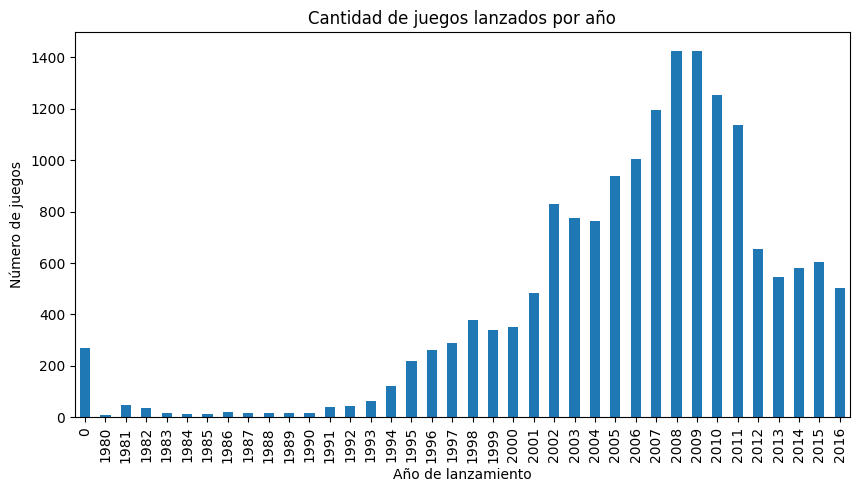

In [9]:
#Mira cuántos juegos fueron lanzados en diferentes años. ¿Son significativos los datos de cada período?

games_per_year = games['year_of_release'].value_counts().sort_index()

import matplotlib.pyplot as plt

games_per_year.plot(kind='bar', figsize=(10, 5))
plt.title('Cantidad de juegos lanzados por año')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Número de juegos')
plt.show()



<function matplotlib.pyplot.show(close=None, block=None)>

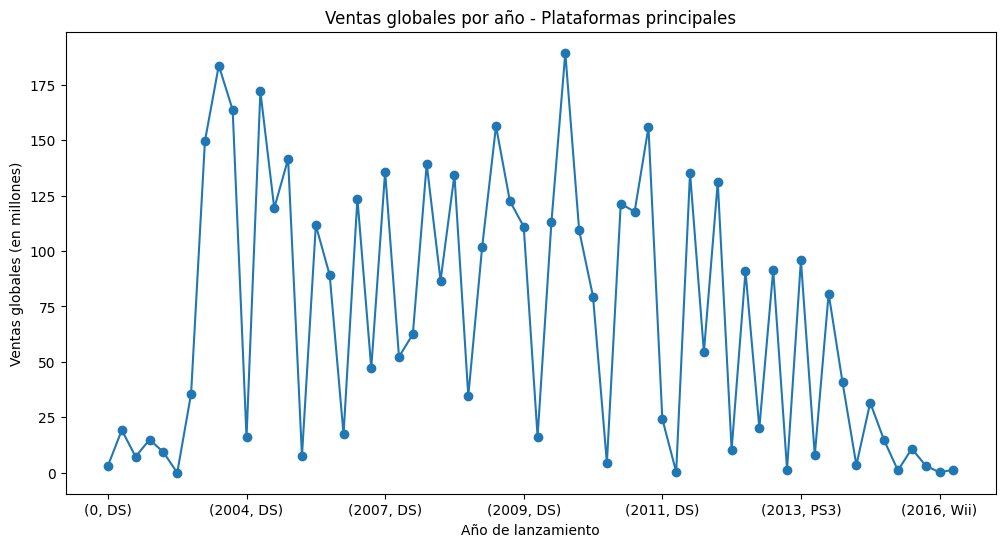

In [10]:
#Observa cómo varían las ventas de una plataforma a otra. Elige las plataformas con las mayores ventas totales y construye una distribución basada en los datos de cada año. Busca las plataformas que solían ser populares pero que ahora no tienen ventas. ¿Cuánto tardan generalmente las nuevas plataformas en aparecer y las antiguas en desaparecer?
games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

top_platforms = games.groupby('platform')['total_sales'].sum().sort_values(ascending=False).head(5).index

df_top = games[games['platform'].isin(top_platforms)]

df_grouped = df_top.groupby(['year_of_release', 'platform'])['total_sales'].sum()

df_grouped.plot(kind='line', figsize=(12,6), marker='o')

plt.title('Ventas globales por año - Plataformas principales')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas globales (en millones)')
plt.show

In [11]:
#Determina para qué período debes tomar datos. Para hacerlo mira tus respuestas a las preguntas anteriores. Los datos deberían permitirte construir un modelo para 2017.




<Figure size 800x400 with 0 Axes>

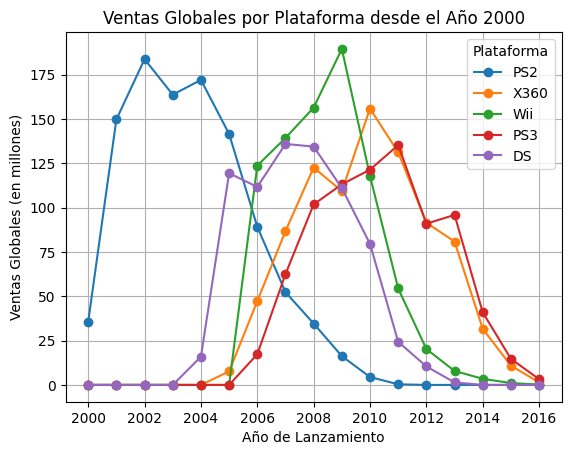

In [12]:
#¿Qué plataformas son líderes en ventas? ¿Cuáles crecen y cuáles se reducen? Elige varias plataformas potencialmente rentables.

platform_sales = games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

df_platform_year = games.groupby(['year_of_release', 'platform'])['total_sales'].sum().unstack().fillna(0)
(df_platform_year)

import matplotlib.pyplot as plt

# Agrupar ventas por año y plataforma
df_platform_year = games.groupby(['year_of_release', 'platform'])['total_sales'].sum().unstack().fillna(0)

# Filtrar solo desde el año 2000 en adelante
df_platform_year = df_platform_year[df_platform_year.index >= 2000]

# Elegir plataformas más vendidas (opcional: top 5 por ventas)
top_platforms = df_platform_year.sum().sort_values(ascending=False).head(5).index
df_top_platforms = df_platform_year[top_platforms]

# Graficar
plt.figure(figsize=(8,4))
df_top_platforms.plot(marker='o')
plt.title('Ventas Globales por Plataforma desde el Año 2000')
plt.xlabel('Año de Lanzamiento')
plt.ylabel('Ventas Globales (en millones)')
plt.grid(True)
plt.legend(title='Plataforma') # Mostrar todos los años como etiquetas
plt.show()


<Figure size 1600x800 with 0 Axes>

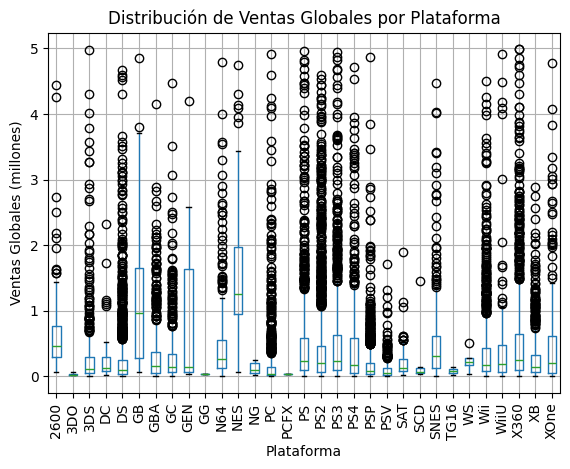

In [13]:
#Crea un diagrama de caja para las ventas globales de todos los juegos, desglosados por plataforma. ¿Son significativas las diferencias en las ventas? ¿Qué sucede con las ventas promedio en varias plataformas? Describe tus hallazgos.

import matplotlib.pyplot as plt

# Filtrar datos relevantes
df_boxplot = games[['platform', 'total_sales']].dropna()

# Limitar ventas muy extremas para mejor visualización (opcional)
df_boxplot = df_boxplot[df_boxplot['total_sales'] < 5]  # elimina outliers extremos

# Crear gráfico de caja
plt.figure(figsize=(16, 8))
df_boxplot.boxplot(column='total_sales', by='platform', rot=90)
plt.title('Distribución de Ventas Globales por Plataforma')
plt.suptitle('')  # quitar título automático de pandas
plt.xlabel('Plataforma')
plt.ylabel('Ventas Globales (millones)')
plt.grid(True)
plt.show()


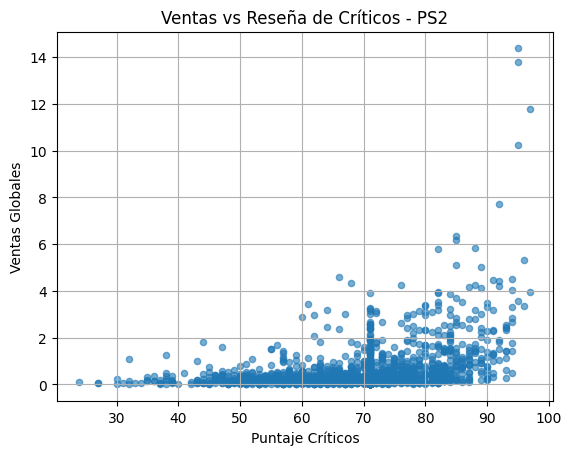

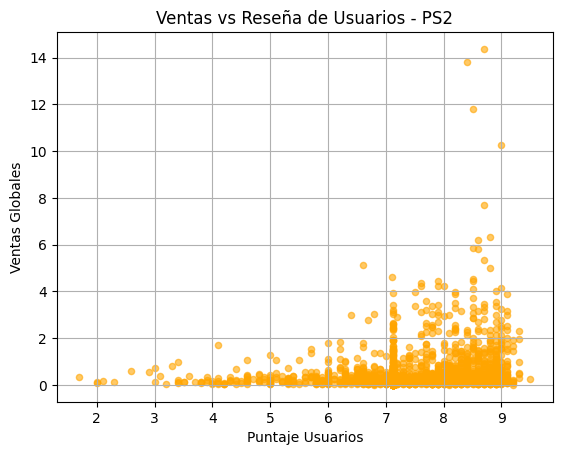

Correlación (Críticos vs Ventas): 0.35419805293279016
Correlación (Usuarios vs Ventas): 0.22350070284132975


In [14]:
#Mira cómo las reseñas de usuarios y profesionales afectan las ventas de una plataforma popular (tu elección). Crea un gráfico de dispersión y calcula la correlación entre las reseñas y las ventas. Saca conclusiones. 

games_filter = games[games['platform'] == 'PS2']
games_filter= games_filter.dropna(subset=['critic_score', 'user_score', 'total_sales'])

import matplotlib.pyplot as plt

# Reseñas de críticos vs ventas
games_filter.plot(x='critic_score', y='total_sales', kind='scatter', alpha=0.6)
plt.title('Ventas vs Reseña de Críticos - PS2')
plt.xlabel('Puntaje Críticos')
plt.ylabel('Ventas Globales')
plt.grid(True)
plt.show()

# Reseñas de usuarios vs ventas
games_filter.plot(x='user_score', y='total_sales', kind='scatter', alpha=0.6, color='orange')
plt.title('Ventas vs Reseña de Usuarios - PS2')
plt.xlabel('Puntaje Usuarios')
plt.ylabel('Ventas Globales')
plt.grid(True)
plt.show()

print('Correlación (Críticos vs Ventas):', games_filter['critic_score'].corr(games_filter['total_sales']))
print('Correlación (Usuarios vs Ventas):', games_filter['user_score'].corr(games_filter['total_sales']))

# Tenemos una correlacion positiva mayor para la grafica de ventas vs reseña de criticos es decir, es miuy leve pero podemos decir que a medida que sube la puntuacion de los criticos, las ventas igual.

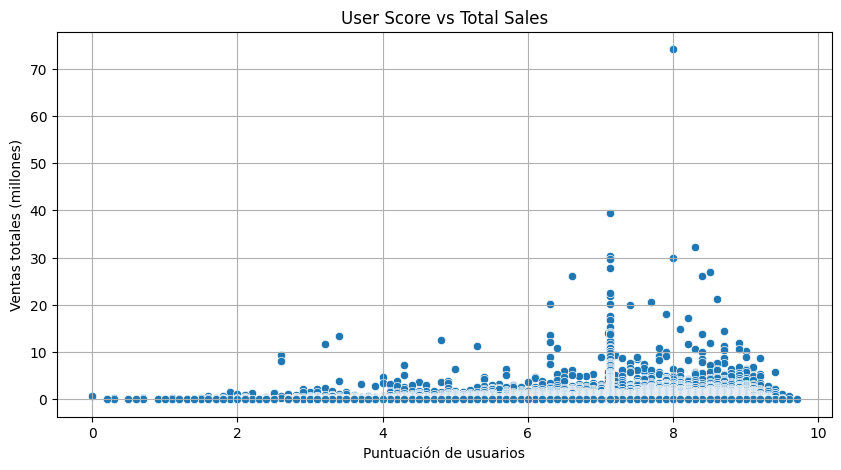

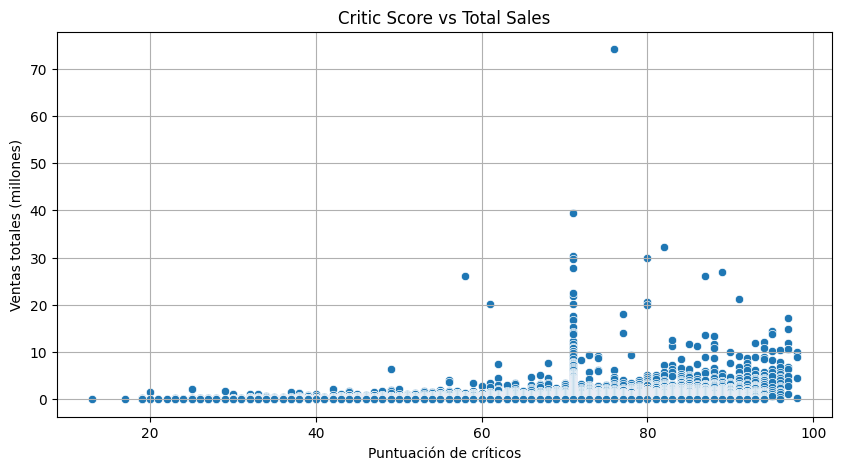

Correlación entre 'user_score' y 'total_sales': 0.07180110269351699
Correlación entre 'critic_score' y 'total_sales': 0.18533595919965434


In [15]:
#Teniendo en cuenta tus conclusiones compara las ventas de los mismos juegos en otras plataformas.

multi_platform_games = games.groupby('name')['platform'].nunique()
multi_platform_games = multi_platform_games[multi_platform_games > 1].index

df_multi = games[games['name'].isin(multi_platform_games)]

sales_per_platform = df_multi.groupby(['name', 'platform'])['total_sales'].sum().reset_index()
reviews = df_multi.groupby(['name', 'platform'])[['user_score', 'critic_score']].mean().reset_index()

comparacion = pd.merge(sales_per_platform, reviews, on=['name', 'platform'])

import matplotlib.pyplot as plt
import seaborn as sns

# Filtramos datos válidos para evitar errores en el scatter plot y la correlación
filtered_df = games[['user_score', 'critic_score', 'total_sales']].dropna()

# Crear gráfico de dispersión: user_score vs total_sales
plt.figure(figsize=(10, 5))
sns.scatterplot(data=filtered_df, x='user_score', y='total_sales')
plt.title('User Score vs Total Sales')
plt.xlabel('Puntuación de usuarios')
plt.ylabel('Ventas totales (millones)')
plt.grid(True)
plt.show()

# Crear gráfico de dispersión: critic_score vs total_sales
plt.figure(figsize=(10, 5))
sns.scatterplot(data=filtered_df, x='critic_score', y='total_sales')
plt.title('Critic Score vs Total Sales')
plt.xlabel('Puntuación de críticos')
plt.ylabel('Ventas totales (millones)')
plt.grid(True)
plt.show()

# Calcular correlaciones
user_corr = filtered_df['user_score'].corr(filtered_df['total_sales'])
critic_corr = filtered_df['critic_score'].corr(filtered_df['total_sales'])

print(f"Correlación entre 'user_score' y 'total_sales': {user_corr}")
print(f"Correlación entre 'critic_score' y 'total_sales': {critic_corr}")


In [16]:
#Echa un vistazo a la distribución general de los juegos por género. ¿Qué se puede decir de los géneros más rentables? ¿Puedes generalizar acerca de los géneros con ventas altas y bajas?

genre_games = games['genre'].value_counts().sort_values(ascending= False)

genre_games

genre
Action          3369
Sports          2348
Misc            1750
Role-Playing    1498
Shooter         1323
Adventure       1303
Racing          1249
Platform         888
Simulation       873
Fighting         849
Strategy         683
Puzzle           580
Name: count, dtype: int64

Paso 4. Crea un perfil de usuario para cada región



Top 5 plataformas en NA:
          na_sales  eu_sales  jp_sales
platform                              
X360        602.47    270.76     12.43
PS2         583.84    339.29    139.20
Wii         496.90    262.21     69.33
PS3         393.49    330.29     80.19
DS          382.40    188.89    175.57

Top 5 plataformas en EU:
          na_sales  eu_sales  jp_sales
platform                              
PS2         583.84    339.29    139.20
PS3         393.49    330.29     80.19
X360        602.47    270.76     12.43
Wii         496.90    262.21     69.33
PS          336.52    213.61    139.82

Top 5 plataformas en JP:
          na_sales  eu_sales  jp_sales
platform                              
DS          382.40    188.89    175.57
PS          336.52    213.61    139.82
PS2         583.84    339.29    139.20
SNES         61.23     19.04    116.55
3DS          83.49     61.48    100.67
Top 5 géneros en NA:
          na_sales  eu_sales  jp_sales
genre                                 
Actio

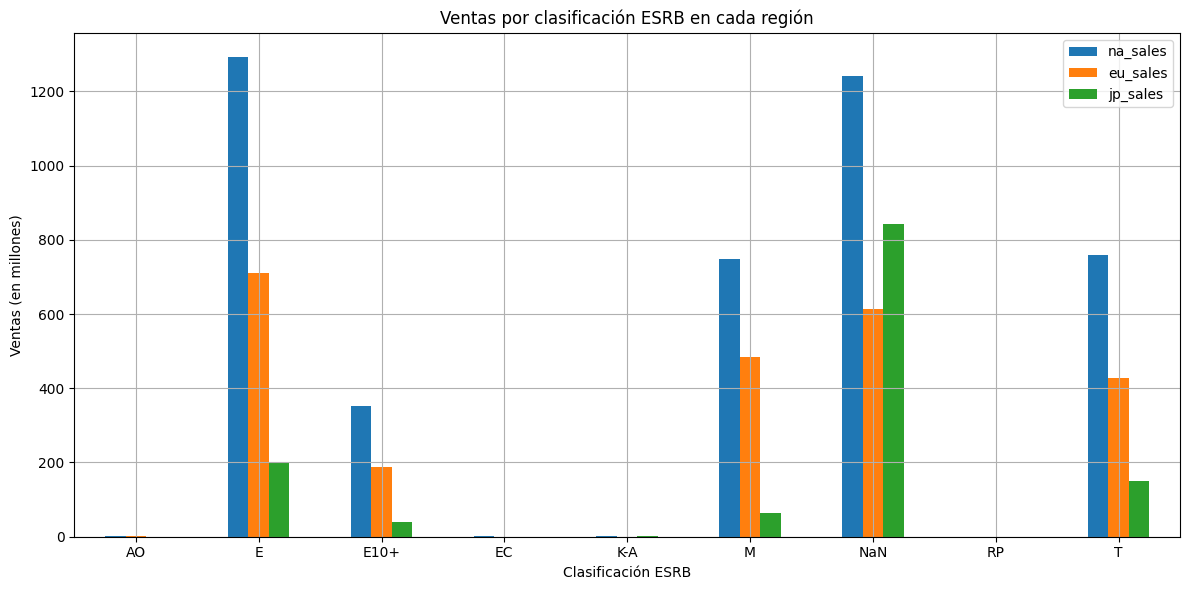

In [17]:
#Para cada región (NA, UE, JP) determina:

#Las cinco plataformas principales. Describe las variaciones en sus cuotas de mercado de una región a otra.
#Los cinco géneros principales. Explica la diferencia.
#Si las clasificaciones de ESRB afectan a las ventas en regiones individuales.



platform_sales = games.groupby('platform')[['na_sales', 'eu_sales', 'jp_sales']].sum()


top5_na = platform_sales.sort_values('na_sales', ascending=False).head(5)
top5_eu = platform_sales.sort_values('eu_sales', ascending=False).head(5)
top5_jp = platform_sales.sort_values('jp_sales', ascending=False).head(5)

print("Top 5 plataformas en NA:")
print(top5_na)
print("\nTop 5 plataformas en EU:")
print(top5_eu)
print("\nTop 5 plataformas en JP:")
print(top5_jp)

#Top genres

genre_sales = games.groupby('genre')[['na_sales', 'eu_sales', 'jp_sales']].sum()

# Obtener top 5 géneros por región
top5_genres_na = genre_sales.sort_values('na_sales', ascending=False).head(5)
top5_genres_eu = genre_sales.sort_values('eu_sales', ascending=False).head(5)
top5_genres_jp = genre_sales.sort_values('jp_sales', ascending=False).head(5)

print("Top 5 géneros en NA:")
print(top5_genres_na)
print("\nTop 5 géneros en EU:")
print(top5_genres_eu)
print("\nTop 5 géneros en JP:")
print(top5_genres_jp)

#ESRB 

# Agrupar por Rating (clasificación ESRB) y sumar ventas por región
rating_sales = games.groupby('rating')[['na_sales', 'eu_sales', 'jp_sales']].sum()

print("Ventas por clasificación ESRB y región:")
print(rating_sales)

# También podrías graficarlo para comparar visualmente
import matplotlib.pyplot as plt

rating_sales.plot(kind='bar', figsize=(12,6))
plt.title('Ventas por clasificación ESRB en cada región')
plt.xlabel('Clasificación ESRB')
plt.ylabel('Ventas (en millones)')
plt.xticks(rotation=0)
plt.grid(True)
plt.tight_layout()
plt.show()


Paso 5. Prueba las siguientes hipótesis:



Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas.
Hipótesis nula (H₀): Las calificaciones promedio de los usuarios para Xbox One y PC son iguales.
                
Hipótesis alternativa (H₁): Las calificaciones promedio de los usuarios para Xbox One y PC son diferentes.
                




In [18]:
import pandas as pd
from scipy.stats import ttest_ind

# Asumiendo que el DataFrame se llama df y las columnas son:
# 'platform', 'genre', 'user_score'

# Asegúrate de convertir user_score a tipo float
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')

# Eliminar NaNs
df_clean = games.dropna(subset=['user_score'])

# 1. Comparar calificaciones promedio: Xbox One vs PC
xbox_scores = df_clean[df_clean['platform'] == 'XOne']['user_score']
pc_scores = df_clean[df_clean['platform'] == 'PC']['user_score']

t_stat1, p_value1 = ttest_ind(xbox_scores, pc_scores, equal_var=False)

print(f"Xbox vs PC - p-value: {p_value1}")

#Las plataformas (Xbox One y PC) muestran calificaciones de usuarios similares - los jugadores no distinguen mucho en su valoración por plataforma.


Xbox vs PC - p-value: 1.0718459399074422e-05


Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes. Establece tu mismo el valor de umbral alfa.

Hipótesis nula (H₀): Las calificaciones promedio de los géneros Action y Sports son iguales.
Hipótesis alternativa (H₁): Las calificaciones promedio de los géneros Action y Sports son diferentes.

In [19]:
import pandas as pd
from scipy.stats import ttest_ind

# Asumiendo que el DataFrame se llama df y las columnas son:
# 'platform', 'genre', 'user_score'

# Asegúrate de convertir user_score a tipo float
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')

# Eliminar NaNs
df_clean = games.dropna(subset=['user_score'])

# 2. Comparar calificaciones promedio: Action vs Sports
action_scores = df_clean[df_clean['genre'] == 'Action']['user_score']
sports_scores = df_clean[df_clean['genre'] == 'Sports']['user_score']

t_stat2, p_value2 = ttest_ind(action_scores, sports_scores, equal_var=False)

# Mostrar resultados
print(f"Action vs Sports - p-value: {p_value2}")

# Evaluación con alfa = 0.05
alpha = 0.05

#Los géneros (Acción y Deportes) sí muestran diferencias claras en las calificaciones - los usuarios perciben estos géneros de manera distinta.

Action vs Sports - p-value: 0.1878227241619564


Paso 6. Escribe una conclusión general


Los géneros (Acción y Deportes) sí muestran diferencias claras en las calificaciones → los usuarios perciben estos géneros de manera distinta.

El análisis del mercado de videojuegos muestra que las plataformas tienen un ciclo de vida claro: aparecen, crecen, alcanzan un pico de popularidad y luego desaparecen, generalmente en un período de 8 a 10 años. Las ventas varían según la región, con géneros como Acción, Deportes y Shooter dominando en Norteamérica y Europa, mientras que en Japón los RPG tienen mayor relevancia. Las reseñas de usuarios y críticos influyen en las ventas, aunque su impacto no es decisivo por sí solo. También se observó que la clasificación ESRB afecta de forma distinta en cada región: más en NA y Europa, menos en Japón. En conclusión, la combinación de factores como plataforma, género, región y calificaciones permite comprender mejor el comportamiento del mercado y anticipar tendencias para tomar decisiones estratégicas.